In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
PALETTE = sns.color_palette("Set2", 5)

os.makedirs("../figuras/seleccion", exist_ok=True)

resultados = pd.DataFrame({
    "modelo": [
        "XGBoost",
        "Regresión Logística",
        "MLP (Keras)",
        "Random Forest",
        "Árbol de Decisión"
    ],
    "pr_auc": [0.0789, 0.0783, 0.0726, 0.0724, 0.0719],
    "recall": [0.5669, 0.6798, 0.5722, 0.3570, 0.6745],        #ponemos en un DataFrame los valores obtenidos de la tabla de metricas y tiempo de entrenamiento de los modelos
    "roc_auc": [0.6150, 0.6179, 0.6043, 0.6064, 0.6051],
    "tiempo_s": [85.2, 5.4, 211.0, 306.6, 109.0]
})

shap = pd.DataFrame({
    "modelo": [
        "Regresión Logística",
        "Árbol de Decisión",
        "Random Forest",
        "XGBoost",
        "MLP (Keras)"
    ],
    "category_Grocery": [41.55, 28.12, 15.68, 22.43, 15.96],
    "shipping_cost": [23.46, 27.74, 12.59, 16.46, 9.74],        #ponemos en un DataFrame los valores obtenidos de la concentracion SHAP de las variables principales para cada modelo que obtuvimos en el notebook de SHAP
    "category_Fashion": [21.42, 18.79, 12.62, 12.12, 12.18]
})

shap["shap_top3_pct"] = shap[
    ["category_Grocery", "shipping_cost", "category_Fashion"]  #suma la importancia SHAP de los 3 variables principales para cada modelo
].sum(axis=1)

resultados = resultados.merge(
    shap[["modelo", "shap_top3_pct"]],      #Unimos las 2 tablas a traves de la columnna modelo
    on="modelo"
)

resultados = resultados.sort_values("pr_auc", ascending=False) #ordenamos la tabla en funcion del PR-AUC obtenido de cada modelo

resultados.round(4)

,modelo,pr_auc,recall,roc_auc,tiempo_s,shap_top3_pct
0,XGBoost,0.0789,0.5669,0.6150,85.2,51.01
1,Regresión Logística,0.0783,0.6798,0.6179,5.4,86.43
2,MLP (Keras),0.0726,0.5722,0.6043,211.0,37.88
3,Random Forest,0.0724,0.3570,0.6064,306.6,40.89
4,Árbol de Decisión,0.0719,0.6745,0.6051,109.0,74.65


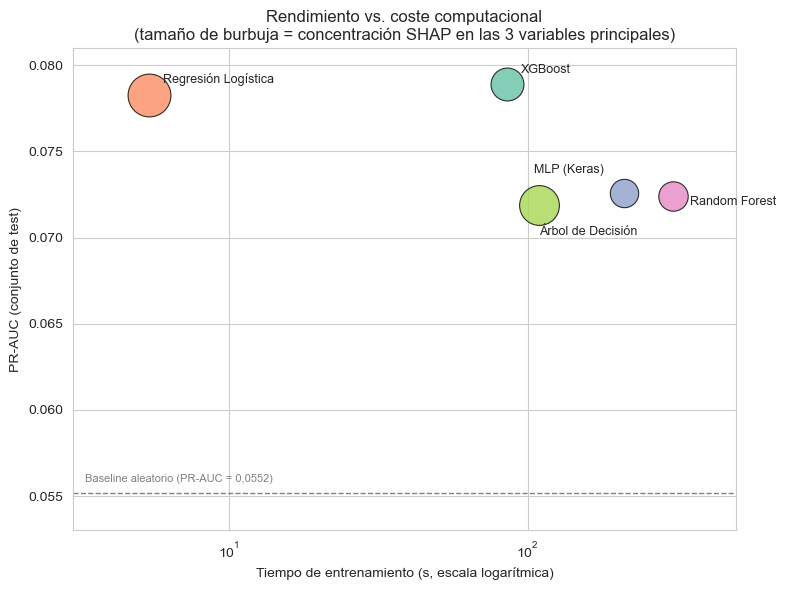

In [2]:
#Grafico para comparacion de los modelos
fig, ax = plt.subplots(figsize=(8, 6))

# Desplazamientos manuales de las etiquetas para evitar solapes entre ellas 
label_offsets = {
    "XGBoost": (10, 8),
    "Regresión Logística": (10, 8),
    "Árbol de Decisión": (0, -22),
    "MLP (Keras)": (-15, 14),
    "Random Forest": (12, -6),
}

for i, row in resultados.iterrows():               #recorrelos datos de cada modelo. fila obtiene los datos de metricas, tiempo de entrenamiento y acumulacion SHAP
    ax.scatter(
        row["tiempo_s"],
        row["pr_auc"],
        s=row["shap_top3_pct"] * 11,                #Dibuja las burbujas de cada modelo donde la coordenada x es el tiempo de entrenamiento, la coordendada y es el PR-AUC del modelo y el tamaño de la burbuja la acumalacion SHAP calculada
        color=PALETTE[i],
        alpha=0.8,
        edgecolor="black",
        linewidth=0.8,
        zorder=3,
    )

    dx, dy = label_offsets[row["modelo"]]

    ax.annotate(
        row["modelo"],
        (row["tiempo_s"], row["pr_auc"]),
        xytext=(dx, dy),                              #Poner nombre de los modelos junto a sus burbujas correspondientes
        textcoords="offset points",
        fontsize=9,
        ha="left" if dx >= 0 else "right",
    )


#baseline aleatorio
ax.axhline(
    0.0552,
    color="gray",
    linestyle="--",
    linewidth=1,
    zorder=1
)

ax.text(
    3.3,
    0.0558,
    "Baseline aleatorio (PR-AUC = 0,0552)",
    fontsize=8,
    color="gray"
)

ax.set_xscale("log")
ax.set_xlim(3, 500)
ax.set_ylim(0.053, 0.081)

ax.set_xlabel("Tiempo de entrenamiento (s, escala logarítmica)")
ax.set_ylabel("PR-AUC (conjunto de test)")

ax.set_title(
    "Rendimiento vs. coste computacional\n"
    "(tamaño de burbuja = concentración SHAP en las 3 variables principales)"
)

plt.tight_layout()

plt.savefig(
    "../figuras/seleccion/comparacion_rendimiento_coste_interpretabilidad.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()